<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"></ul></div>

Compare analytical results with numerical results using truncated Floquet matrices. 

In [1]:
import numpy as np
from scipy import integrate
from scipy.special import jv
from scipy.linalg import expm, inv
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": 'Arial', 
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.titlesize": 18
})

np.set_printoptions(precision=6, suppress=True)

In [2]:
twopi = 2 * np.pi

######### Atomic Units #########
################################
## Charge: e > 0              ##
## Ang. momentum: hbar        ##
## Mass: m_e                  ##
## Permittivity: 4 pi eps_0   ## 
## Temperature: 1 K           ##
################################
################################

# Values in SI
e_mass = 9.1093837e-31                                            # electron mass
e_charge = 1.6021766e-19                                          # positron charge
hbar = 1.0545718e-34                                              # reduced Planck's constant
eps_0 = 8.8541878e-12                                             # Free space permittivity
kb = 1.380649e-23                                                 # Boltzmann constant
Eh = e_mass * e_charge**4 * (2 * twopi * eps_0)**-2 * hbar**-2    # Hartree (4.360e-18)

# useful conversion
kb_atomic = kb / Eh                                               # (3.167e-06)
ev_atomic = e_charge / Eh                                         # (0.0367)
THz_atomic = 10**12 * (hbar * twopi) / Eh                         # (1.520e-4)

In [4]:
default_params = {
    "NF": 60,                       # 2*NF+1 is the size of truncated Floquet matrices
    "chem1": 20 * THz_atomic,       # chemical potential (bath 1)
    "temp1": 300,                   # temperature (bath 1)
    "Gamma1": 0.50 * THz_atomic,    # damping due to self-energy (bath 1)
    "chem2": -20 * THz_atomic,      # chemical potential (bath 2)
    "temp2": 300,                   # temperature (bath 2)
    "Gamma2": 0.75 * THz_atomic,    # damping due to self-energy (bath 2)
    "eps0": 0 * THz_atomic,         # undriven energy level
    "eps1": 90 * THz_atomic,        # half of driving amplitude
    "Omega": 500 * THz_atomic,      # driving frequency
}

damped_params2 = default_params.copy()
damped_params2["Gamma1"] *= 2
damped_params2["Gamma2"] *= 2

damped_params3 = default_params.copy()
damped_params3["Gamma1"] *= 3
damped_params3["Gamma2"] *= 3

Floquet representation

\begin{align*}
    G_{mn}(\omega) = \frac{1}{T} \int_0^T d t_1 \int_{-\infty}^\infty d t_2 \, e^{i (m\Omega + \omega) t_1} e^{-i (n\Omega + \omega) t_2} G(t_1, t_2)
\end{align*}

Inversion

\begin{align*}
    G(t_1, t_2) &= \frac{1}{2\pi} \sum_{mn} \int_{-\Omega/2}^{\Omega/2} d \omega \, e^{-i(m\Omega+\omega) t_1} e^{i(n\Omega+\omega) t_2} G_{mn}(\omega) \\
    G(t, t) &= \frac{1}{2\pi} \sum_{mn} \int_{-\Omega/2}^{\Omega/2} d \omega \, e^{-i (m-n) \Omega t} G_{mn}(\omega) 
\end{align*}

In [5]:
# assume quantity in time domain is 1x1
def floquet_to_time_integrand(omega, func, t, params):
    # func(omega, params) returns a matrix of size (2*NF+1,2*NF+1)
    
    NF = params["NF"]
    Omega = params["Omega"]
    
    Ohm0 = np.diag(
        np.arange(-NF,NF+1) * Omega
    )
    
    U = expm(-1j * t * Ohm0)
        
    G = U @ func(omega, params) @ U.conj().T
    
    return G.sum().real
    
def floquet_to_time_integral(func, t, params):
    Omega = params["Omega"]
    
    res, _ = integrate.quad(lambda w: floquet_to_time_integrand(w, func, t, params), 
                            -Omega/2, Omega/2)
    
    return res/twopi

Simplest periodic Hamiltonian

\begin{align*}
  H(t) = \epsilon_0 + 2 \epsilon_1 \cos \Omega t
\end{align*}

Hamiltonian in Floquet representation 
\begin{align}
    \mathbf{H} &= \begin{pmatrix}
        \ddots & & & & \\ 
        & \epsilon_0 & \epsilon_{1} & 0 & \\
        & \epsilon_{1} & \epsilon_0 & \epsilon_{1} & \\
        & 0 & \epsilon_{1} & \epsilon_0 & \\
        & & & & \ddots
    \end{pmatrix}
\end{align}

In [8]:
def H_floquet(params):
    NF = params["NF"]
    eps0 = params["eps0"]
    eps1 = params["eps1"]
    
    H = eps0 * np.eye(2*NF+1)
    np.fill_diagonal(H[1:], eps1)
    np.fill_diagonal(H[:,1:], eps1)
    
    return H

Floquet omega

\begin{align}
    \mathbf{\Omega} &= \begin{pmatrix}
        \ddots & & & & \\ 
        & \omega-\Omega & & & \\
        & & \omega & & \\
        & & & \omega+\Omega & \\
        & & & & \ddots
    \end{pmatrix}
\end{align}

In [9]:
def omega_floquet(omega, params):
    NF = params["NF"]
    Omega = params["Omega"]
    
    Ohm = np.diag(np.arange(-NF,NF+1) * Omega + omega)
    
    return Ohm

Fermi function in Floquet representation 

\begin{align*}
    \mathbf{F} &= \begin{pmatrix}
        \ddots & & & & \\ 
        & f(\hbar (\omega-\Omega)) & 0 & 0 & \\
        & 0 & f(\hbar \omega) & 0 & \\
        & 0 & 0 & f(\hbar (\omega+\Omega)) & \\
        & & & & \ddots
    \end{pmatrix}
\end{align*}

In [10]:
def fermi(omega, chem, temp):
    expo = np.minimum(99, (omega-chem)/(kb_atomic*temp)) # prevent overflow
    return 1/(np.exp(expo) + 1)

def F_floquet(omega, params, mode="1"):
    NF = params["NF"]
    L = 2*NF+1
    Omega = params["Omega"]
    
    if mode == "1":
        chem = params["chem1"]
        temp = params["temp1"]
    elif mode == "2":
        chem = params["chem2"]
        temp = params["temp2"]
    
    F = np.zeros((L,L))
    
    for l in range(L):
        n = l - NF
        F[l,l] = fermi(omega+n*Omega, chem, temp)
        
    return F

Floquet Green functions

\begin{align*}
    \mathbf{G}^R &= (\hbar\mathbf{\Omega} - \mathbf{H} + i \Gamma/2)^{-1} \\
    \mathbf{G}^A &= (\mathbf{G}^R)^\dagger 
\end{align*}

In [13]:
def GR_floquet(omega, params, mode="1"):
    NF = params["NF"]
    Omega = params["Omega"]
    
    if mode == "1":
        Gamma = params["Gamma1"]
    elif mode == "2":
        Gamma = params["Gamma2"]
    elif mode == "both":
        Gamma = params["Gamma1"] + params["Gamma2"]
        
    H = H_floquet(params)
    Ohm = omega_floquet(omega, params)
    I = np.eye(2*NF+1)
    
    return inv(Ohm - H  + 0.5j * Gamma * I)

Population

\begin{align}
    \mathbf{\Sigma}^< &= i \Gamma \mathbf{F} \\
    \mathbf{G}^< &= \mathbf{G}^R \mathbf{\Sigma}^< \mathbf{G}^A \\
    \rho(t) &= -i \hbar G^<(t,t)
\end{align}

In [17]:
def rho_floquet(omega, params, mode="1"):
    SigmaLess_im1 = params["Gamma1"] * F_floquet(omega, params, mode="1")
    SigmaLess_im2 = params["Gamma2"] * F_floquet(omega, params, mode="2")
    
    if mode == "1":
        SigmaLess_im = SigmaLess_im1
    elif mode == "2":
        SigmaLess_im = SigmaLess_im2
    else:
        SigmaLess_im = SigmaLess_im1 + SigmaLess_im2
    
    GR = GR_floquet(omega, params, mode=mode)
    GA = GR.conj().T
    
    return GR @ SigmaLess_im @ GA

In [18]:
# analytical solution
def rho_floquet_analytical(params, mode="1"):
    eps0 = params["eps0"]
    eps1 = params["eps1"]
    Omega = params["Omega"]
    
    if mode == "1":
        chem = params["chem1"]
        temp = params["temp1"]
    elif mode == "2":
        chem = params["chem2"]
        temp = params["temp2"]
    else:
        Gamma1 = params["Gamma1"]
        Gamma2 = params["Gamma2"]
        
        return (
            (Gamma1 * rho_floquet_analytical(params, mode="1")
            + Gamma2 * rho_floquet_analytical(params, mode="2"))
            /(Gamma1 + Gamma2)
        )
    
    NF = 100
    strength = 2 * eps1 / Omega
    
    res = fermi(eps0, chem, temp) * jv(0, strength)**2
    
    for xi in range(1,NF):
        res += (
            fermi(eps0 + xi * Omega, chem, temp) 
            + fermi(eps0 - xi * Omega, chem, temp) 
        ) * jv(xi, strength)**2
        
    return res

In [19]:
%%time

Omega = default_params["Omega"]
t_values_normalized = np.linspace(0, 1, 20)
t_values = t_values_normalized * twopi/Omega

rho_values_default = [floquet_to_time_integral(rho_floquet, t, default_params) for t in t_values]
rho_values_damped2 = [floquet_to_time_integral(rho_floquet, t, damped_params2) for t in t_values]
rho_values_damped3 = [floquet_to_time_integral(rho_floquet, t, damped_params3) for t in t_values]

Wall time: 19min 29s


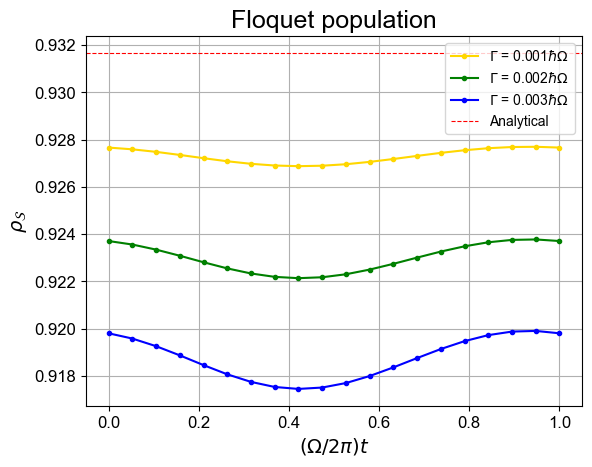

In [20]:
plt.plot(t_values_normalized, rho_values_default, marker='.', color="gold", 
         label=rf"$\Gamma$ = {default_params['Gamma1']/Omega:.2g}$\hbar\Omega$")
plt.plot(t_values_normalized, rho_values_damped2, marker='.', color="green", 
         label=rf"$\Gamma$ = {damped_params2['Gamma1']/Omega:.2g}$\hbar\Omega$")
plt.plot(t_values_normalized, rho_values_damped3, marker='.', color="blue", 
         label=rf"$\Gamma$ = {damped_params3['Gamma1']/Omega:.2g}$\hbar\Omega$")

analytical = rho_floquet_analytical(default_params, mode="1")
plt.axhline(y=analytical, color='red', linestyle='--', linewidth=0.8, label="Analytical")
# plt.ylim(analytical-0.01, analytical+0.01) 

plt.xlabel("$(\Omega/2\pi) t$")
plt.ylabel(r"$\rho_\mathcal{S}$")
plt.legend()
plt.title(rf"Floquet population")
plt.grid(True)
plt.savefig("population_numerical.pdf", format="pdf")

In [21]:
print(rf'$\hbar\Omega$={Omega/ev_atomic:.3g} eV')
print(rf'$\epsilon_0$={default_params["eps0"]/ev_atomic:.3g} eV')
print(rf'$\epsilon_1$={default_params["eps1"]/ev_atomic:.3g} eV')
print(rf'$\mu$={default_params["chem1"]/ev_atomic:.3g} eV')
print(rf'$k_B T$={kb_atomic * default_params["temp1"]/ev_atomic:.3g} eV')

$\hbar\Omega$=2.07 eV
$\epsilon_0$=0 eV
$\epsilon_1$=0.372 eV
$\mu$=0.0827 eV
$k_B T$=0.0259 eV


Current (Normalized)

\begin{align}
    \frac{\hbar J}{\Gamma_L + \Gamma_R} 
    = \frac{2 \hbar}{\Gamma_L + \Gamma_R} \Re \operatorname{Tr}_t 
    [ \mathbf{G}^R \mathbf{\Sigma}_L^< + \mathbf{G}^< \mathbf{\Sigma}_L^A ]
\end{align}

AC component
\begin{align}
    \frac{\hbar J}{\Gamma_L + \Gamma_R} 
    = \frac{2 \hbar}{\Gamma_L + \Gamma_R} \Re \operatorname{Tr}_t 
    [ \mathbf{G}^R \mathbf{\Sigma}_L^< \mathbf{G}^A (\hbar\mathbf{\Omega} - \mathbf{H})]
\end{align}

DC component
\begin{align}
    \frac{\hbar J}{\Gamma_L + \Gamma_R} 
    = \frac{\hbar \Gamma_L \Gamma_R}{\Gamma_L + \Gamma_R} \Re \operatorname{Tr}_t 
    [\mathbf{G}^R (\mathbf{F}_L - \mathbf{F}_R) \mathbf{G}^A]
\end{align}

Analytical
\begin{align}
    \frac{\hbar J}{\Gamma_L + \Gamma_R} 
    = \frac{\Gamma_L}{\Gamma_L + \Gamma_R} \frac{\Gamma_R}{\Gamma_L + \Gamma_R} 
    \operatorname{Tr} (\rho_L - \rho_R)
\end{align}

In [22]:
def J_floquet(omega, params):
    Gamma1 = params["Gamma1"]
    Gamma2 = params["Gamma2"]
    
    GR = GR_floquet(omega, params, mode="both")
    GA = GR.conj().T
    SigmaLess1 = 1j * Gamma1 * F_floquet(omega, params, mode="1")
    SigmaLess2 = 1j * Gamma2 * F_floquet(omega, params, mode="2")
    
    GLess = GR @ (SigmaLess1 + SigmaLess2) @ GA
    SigmaA1 = 0.5j * Gamma1
    
    return 2/(Gamma1+Gamma2) * (GR @ SigmaLess1 + GLess * SigmaA1).real

In [23]:
def J_floquet_DC(omega, params):
    Gamma1 = params["Gamma1"]
    Gamma2 = params["Gamma2"]
    
    GR = GR_floquet(omega, params, mode="both")
    GA = GR.conj().T
    F1 = F_floquet(omega, params, mode="1")
    F2 = F_floquet(omega, params, mode="2")
    
    return Gamma1*Gamma2/(Gamma1+Gamma2) * (GR @ (F1-F2) @ GA).real

In [24]:
def J_floquet_AC(omega, params):
    Gamma1 = params["Gamma1"]
    Gamma2 = params["Gamma2"]
    
    GR = GR_floquet(omega, params, mode="both")
    GA = GR.conj().T
    SigmaLess1 = 1j * Gamma1 * F_floquet(omega, params, mode="1")
    
    H = H_floquet(params)
    Ohm = omega_floquet(omega, params)
    
    return 2/(Gamma1+Gamma2)*(GR @ SigmaLess1 @ GA @ (Ohm-H)).real

In [25]:
def J_floquet_analytical(params):
    Gamma1 = params["Gamma1"]
    Gamma2 = params["Gamma2"]
    
    rho1 = rho_floquet_analytical(params, mode="1")
    rho2 = rho_floquet_analytical(params, mode="2")
    
    return Gamma1*Gamma2/(Gamma1+Gamma2)**2 * (rho1 - rho2)

In [27]:
%%time
Omega = default_params["Omega"]
t_values_normalized = np.linspace(0, 1, 50)
t_values = t_values_normalized * twopi/Omega

J_values_default = [floquet_to_time_integral(J_floquet, t, default_params) for t in t_values]
J_values_AC_default = [floquet_to_time_integral(J_floquet_AC, t, default_params) for t in t_values]
J_values_DC_default = [floquet_to_time_integral(J_floquet_DC, t, default_params) for t in t_values]

Wall time: 43min 56s


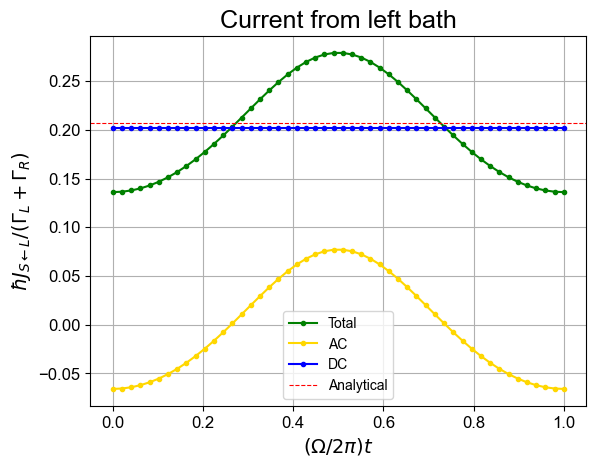

In [28]:
plt.plot(t_values_normalized, J_values_default, marker='.', color="green", 
         label=rf"Total")
plt.plot(t_values_normalized, J_values_AC_default, marker='.', color="gold", 
         label=rf"AC")
plt.plot(t_values_normalized, J_values_DC_default, marker='.', color="blue", 
         label=rf"DC")

analytical = J_floquet_analytical(default_params)
plt.axhline(y=analytical, color='red', linestyle='--', linewidth=0.8, label="Analytical")
# plt.ylim(-0.03, +0.03) 

plt.xlabel("$(\Omega/2\pi) t$")
plt.ylabel(r"$\hbar J_{S \leftarrow L}/(\Gamma_L+\Gamma_R)$")
plt.legend()
plt.title(rf"Current from left bath")
plt.grid(True)
plt.savefig("current_numerical.pdf", format="pdf")

In [31]:
print(rf'$\hbar\Omega$={Omega/ev_atomic:.3g} eV')
print(rf'$\epsilon_0$={default_params["eps0"]/ev_atomic:.3g} eV')
print(rf'$\epsilon_1$={default_params["eps1"]/ev_atomic:.3g} eV')
print(rf'$\mu_1$={default_params["chem1"]/ev_atomic:.3g} eV')
print(rf'$\mu_2$={default_params["chem2"]/ev_atomic:.3g} eV')
print(rf'$k_B T$={kb_atomic * default_params["temp1"]/ev_atomic:.3g} eV')
print(rf'$\Gamma_L$ = {default_params["Gamma1"]/Omega:.2g}$\hbar\Omega$')
print(rf'$\Gamma_R$ = {default_params["Gamma2"]/Omega:.2g}$\hbar\Omega$')

$\hbar\Omega$=2.07 eV
$\epsilon_0$=0 eV
$\epsilon_1$=0.372 eV
$\mu_1$=0.0827 eV
$\mu_2$=-0.0827 eV
$k_B T$=0.0259 eV
$\Gamma_L$ = 0.001$\hbar\Omega$
$\Gamma_R$ = 0.0015$\hbar\Omega$
